# 02 - Pronóstico Avanzado de Demanda (Mezcla de Modelos)

**Caso de negocio:** predecir la demanda semanal de cada SKU sobre **174 semanas**
de historia para anticipar campañas y planificar el abastecimiento.

**Enfoque avanzado:**
1. **Ingeniería de características de series de tiempo** por SKU: rezagos (lags),
   medias y desviaciones móviles, estacionalidad anual (seno/coseno) y tendencia.
2. **Variables externas**: clima (normales climatológicas de Costa Rica),
   promociones/campañas (incluida la anticipación a la campaña) y precio (costo
   unitario), que enriquecen la señal más allá del histórico de demanda.
3. **Tres modelos** de Spark MLlib: `LinearRegression`, `RandomForestRegressor`
   y `GBTRegressor` (Gradient Boosting), con hiperparámetros ajustados por
   **validación cruzada temporal de ventana expansiva**.
4. **Mezcla de modelos (blending)**: combinación ponderada por el inverso del
   error, que suele superar a cualquier modelo individual.
5. Persistimos un pronóstico por SKU que alimenta la **política de
   reabastecimiento** del notebook 04.


In [1]:
import os
import glob
from pyspark.sql import SparkSession, Window
from pyspark.sql import functions as F

# --- Configuracion de entorno para Spark en Windows ---
if not os.environ.get("JAVA_HOME"):
    cand = (glob.glob(r"C:\Program Files\Microsoft\jdk-17*")
            + glob.glob(r"C:\Program Files\Eclipse Adoptium\jdk-17*")
            + glob.glob(os.path.expanduser(r"~\AppData\Local\Microsoft\jdk-17*")))
    if cand:
        os.environ["JAVA_HOME"] = cand[0]
        os.environ["PATH"] = os.path.join(cand[0], "bin") + os.pathsep + os.environ.get("PATH", "")

ROOT = "." if os.path.isdir("hadoop") else ".."
_hh = os.path.abspath(os.path.join(ROOT, "hadoop"))
if os.path.isdir(os.path.join(_hh, "bin")):
    os.environ["HADOOP_HOME"] = _hh
    os.environ["PATH"] = os.path.join(_hh, "bin") + os.pathsep + os.environ.get("PATH", "")

spark = (
    SparkSession.builder
    .appName("Starbucks-Pronostico-Avanzado")
    .master("local[*]")
    .config("spark.sql.shuffle.partitions", "8")
    .config("spark.driver.memory", "3g")
    .getOrCreate()
)
spark.sparkContext.setLogLevel("ERROR")
PARQUET_DIR = os.path.join(ROOT, "data", "parquet")
print("Spark", spark.version, "| Parquet en:", PARQUET_DIR)

Spark 4.1.2 | Parquet en: ..\data\parquet


## 1. Carga de la serie de demanda (174 semanas)


In [2]:
df = spark.read.parquet(os.path.join(PARQUET_DIR, "demanda_larga"))
N_SEM = df.agg(F.max("semana")).first()[0]
print("Filas:", df.count(), "| Semanas:", N_SEM, "| SKUs:", df.select('SKU').distinct().count())
df.show(5)

Filas: 75864 | Semanas: 174 | SKUs: 436


+------+--------------------+--------------------+------+-------+--------------+---------+-------------+----------+
|   SKU|         DESCRIPCION|           PROVEEDOR|semana|demanda|COSTO_UNITARIO|VIDA_UTIL|CS_POR_PALLET|es_campana|
+------+--------------------+--------------------+------+-------+--------------+---------+-------------+----------+
|100396|"BROCHURE HOLDER ...|STARBUCKS CORPORA...|     1|    0.0|          2.74|      0.0|         15.0|         0|
|100396|"BROCHURE HOLDER ...|STARBUCKS CORPORA...|     2|    0.0|          2.74|      0.0|         15.0|         0|
|100396|"BROCHURE HOLDER ...|STARBUCKS CORPORA...|     3|    0.0|          2.74|      0.0|         15.0|         0|
|100396|"BROCHURE HOLDER ...|STARBUCKS CORPORA...|     4|    0.0|          2.74|      0.0|         15.0|         0|
|100396|"BROCHURE HOLDER ...|STARBUCKS CORPORA...|     5|    0.0|          2.74|      0.0|         15.0|         0|
+------+--------------------+--------------------+------+-------+-------

## 2. Ingeniería de características de series de tiempo y variables externas

Para cada SKU, ordenado por semana, generamos:
- **Rezagos** (`lag`): demanda de 1, 2, 4, 13 y 52 semanas atrás.
- **Medias y desviaciones móviles** de las últimas 4 y 13 semanas.
- **Estacionalidad anual** vía seno/coseno de la semana del año.
- **Tendencia** (índice de semana) y atributos de producto.
- **Variables externas**: clima (normales de precipitación de Costa Rica y
  bandera de estación lluviosa), promociones (campaña actual, anticipación a
  campaña en las próximas 4 semanas y temporada alta de retail) y precio
  (costo unitario y su transformación logarítmica).

Descartamos las primeras 52 semanas (sin rezago anual completo).


In [3]:
import math

w = Window.partitionBy("SKU").orderBy("semana")
for L in [1, 2, 4, 13, 52]:
    df = df.withColumn(f"lag_{L}", F.lag("demanda", L).over(w))

w4 = Window.partitionBy("SKU").orderBy("semana").rowsBetween(-4, -1)
w13 = Window.partitionBy("SKU").orderBy("semana").rowsBetween(-13, -1)
df = (
    df.withColumn("roll_mean_4", F.avg("demanda").over(w4))
      .withColumn("roll_mean_13", F.avg("demanda").over(w13))
      .withColumn("roll_std_13", F.stddev("demanda").over(w13))
)

# Estacionalidad: semana dentro del anio (1..52) -> seno y coseno.
df = df.withColumn("sem_anio", ((F.col("semana") - 1) % 52) + 1)
df = (
    df.withColumn("sin_sem", F.sin(2 * math.pi * F.col("sem_anio") / 52.0))
      .withColumn("cos_sem", F.cos(2 * math.pi * F.col("sem_anio") / 52.0))
)

# --- VARIABLES EXTERNAS ------------------------------------------------------
# (a) CLIMA. Mapeamos la semana del anio a un mes y le asociamos las NORMALES
#     CLIMATOLOGICAS del Valle Central de Costa Rica (San Jose): precipitacion
#     media mensual (mm) y estacion seca/lluviosa. Son datos climaticos reales y
#     deterministas por calendario (no inventados), que capturan el efecto del
#     clima en el trafico de tienda y la mezcla de bebidas frias/calientes.
df = df.withColumn("mes", F.least(F.lit(12), (F.floor((F.col("sem_anio") - 1) / 4.333) + 1).cast("int")))
lluvia_norm = {1: 6.0, 2: 10.0, 3: 14.0, 4: 80.0, 5: 230.0, 6: 280.0,
               7: 180.0, 8: 220.0, 9: 305.0, 10: 345.0, 11: 130.0, 12: 35.0}
expr_lluvia = F.lit(35.0)
for m, mm in lluvia_norm.items():
    expr_lluvia = F.when(F.col("mes") == m, F.lit(mm)).otherwise(expr_lluvia)
df = df.withColumn("indice_lluvia", expr_lluvia)
# Estacion lluviosa en Costa Rica: mayo-noviembre (meses 5..11).
df = df.withColumn("estacion_lluviosa",
                   F.when(F.col("mes").between(5, 11), 1).otherwise(0))

# (b) PROMOCIONES. Ademas de la bandera de campana del SKU-semana, anticipamos
#     la campana: 'campana_prox_4' = 1 si el SKU entra en campana en alguna de
#     las proximas 4 semanas (senal para abastecerse antes del pico). Y la
#     'temporada_alta' de retail (noviembre-diciembre).
w_lead4 = Window.partitionBy("SKU").orderBy("semana").rowsBetween(1, 4)
df = df.withColumn("campana_prox_4", F.max("es_campana").over(w_lead4))
df = df.withColumn("temporada_alta",
                   F.when(F.col("mes").isin(11, 12), 1).otherwise(0))

# (c) PRECIO. El costo unitario es la senal de precio disponible en la fuente.
#     Agregamos su transformacion logaritmica (suaviza la fuerte asimetria de
#     precios) util sobre todo para el modelo lineal.
df = df.withColumn("log_costo", F.log1p(F.col("COSTO_UNITARIO")))

# Mantenemos solo filas con historia suficiente (rezago anual disponible).
feat = df.filter(F.col("semana") > 52).fillna(0.0)
print("Filas con caracteristicas completas:", feat.count())
feat.select("SKU", "semana", "demanda", "mes", "indice_lluvia", "estacion_lluviosa",
            "campana_prox_4", "temporada_alta", "log_costo").show(5)


Filas con caracteristicas completas: 53192


+------+------+-------+---+-------------+-----------------+--------------+--------------+------------------+
|   SKU|semana|demanda|mes|indice_lluvia|estacion_lluviosa|campana_prox_4|temporada_alta|         log_costo|
+------+------+-------+---+-------------+-----------------+--------------+--------------+------------------+
|100396|    53|    0.0|  1|          6.0|                0|             0|             0|1.3190856114264407|
|100396|    54|    0.0|  1|          6.0|                0|             0|             0|1.3190856114264407|
|100396|    55|    0.0|  1|          6.0|                0|             0|             0|1.3190856114264407|
|100396|    56|    0.0|  1|          6.0|                0|             0|             0|1.3190856114264407|
|100396|    57|    0.0|  1|          6.0|                0|             0|             0|1.3190856114264407|
+------+------+-------+---+-------------+-----------------+--------------+--------------+------------------+
only showing top 5 

## 3. Pipeline de características y partición temporal

Reservamos las **Últimas 13 semanas** como conjunto de prueba (coincide con el
tiempo de transito de 3 meses que usaremos en el reabastecimiento).

In [4]:
from pyspark.ml import Pipeline
from pyspark.ml.feature import VectorAssembler, StandardScaler

FEATURES = [
    # --- series de tiempo ---
    "lag_1", "lag_2", "lag_4", "lag_13", "lag_52",
    "roll_mean_4", "roll_mean_13", "roll_std_13",
    "sin_sem", "cos_sem", "semana",
    # --- promociones ---
    "es_campana", "campana_prox_4", "temporada_alta",
    # --- clima (normales climatologicas de Costa Rica) ---
    "indice_lluvia", "estacion_lluviosa",
    # --- precio y atributos de producto ---
    "COSTO_UNITARIO", "log_costo", "VIDA_UTIL", "CS_POR_PALLET",
]
assembler = VectorAssembler(inputCols=FEATURES, outputCol="rawFeatures")
scaler = StandardScaler(inputCol="rawFeatures", outputCol="features", withMean=True, withStd=True)
prep = Pipeline(stages=[assembler, scaler]).fit(feat)
datos = prep.transform(feat).cache()

CORTE = N_SEM - 13  # ultimas 13 semanas = prueba
train = datos.filter(F.col("semana") <= CORTE)
test = datos.filter(F.col("semana") > CORTE)
print(f"Corte semana {CORTE} | Entrenamiento: {train.count()} | Prueba: {test.count()}")
print(f"Total de variables predictoras: {len(FEATURES)}")


Corte semana 161 | Entrenamiento: 47524 | Prueba: 5668
Total de variables predictoras: 20


## 4. Validación cruzada temporal y ajuste de hiperparámetros

En series de tiempo **no** se puede usar `CrossValidator` con folds aleatorios:
mezclaría el futuro con el pasado (fuga de información). Implementamos una
**validación cruzada con ventana expansiva** (*rolling/expanding origin*): cada
*fold* entrena con todas las semanas hasta un corte y valida con el bloque de
semanas inmediatamente posterior. Promediamos el RMSE de los *folds* y elegimos,
para cada algoritmo, la combinación de hiperparámetros con menor error.


In [5]:
from pyspark.ml.regression import LinearRegression, RandomForestRegressor, GBTRegressor
from pyspark.ml.evaluation import RegressionEvaluator

ev_rmse = RegressionEvaluator(labelCol="demanda", predictionCol="prediction", metricName="rmse")

# Folds temporales de ventana expansiva DENTRO del entrenamiento (semana <= CORTE).
# (corte_entrenamiento, inicio_validacion, fin_validacion)
FOLDS = [(135, 136, 148), (148, 149, 161)]

def _prep_fit(df_train):
    """Ajusta el ensamblado + estandarizacion SOLO con datos del fold de train
    (evita fuga de informacion del futuro)."""
    a = VectorAssembler(inputCols=FEATURES, outputCol="rawFeatures")
    s = StandardScaler(inputCol="rawFeatures", outputCol="features", withMean=True, withStd=True)
    return Pipeline(stages=[a, s]).fit(df_train)

def cv_temporal(constructor, grid):
    """Evalua cada combinacion de hiperparametros por RMSE promedio en los folds."""
    resultados = []
    for combo in grid:
        rmses = []
        for tr_end, va_ini, va_fin in FOLDS:
            tr = feat.filter((F.col("semana") > 52) & (F.col("semana") <= tr_end))
            va = feat.filter((F.col("semana") >= va_ini) & (F.col("semana") <= va_fin))
            pm = _prep_fit(tr)
            modelo = constructor(combo).fit(pm.transform(tr))
            p = (modelo.transform(pm.transform(va))
                 .withColumn("prediction", F.greatest(F.lit(0.0), F.col("prediction"))))
            rmses.append(ev_rmse.evaluate(p))
        resultados.append((combo, sum(rmses) / len(rmses)))
    resultados.sort(key=lambda x: x[1])
    return resultados

# Rejillas de busqueda (modestas para mantener el costo de computo razonable).
grid_lr = [{"regParam": r, "elasticNetParam": e}
           for r in [0.01, 0.1, 0.3] for e in [0.0, 0.5]]
grid_rf = [{"numTrees": n, "maxDepth": d} for n in [60, 120] for d in [6, 10]]
grid_gbt = [{"maxIter": n, "maxDepth": d} for n in [40, 80] for d in [4, 6]]

res_lr = cv_temporal(lambda c: LinearRegression(featuresCol="features", labelCol="demanda", **c), grid_lr)
res_rf = cv_temporal(lambda c: RandomForestRegressor(featuresCol="features", labelCol="demanda", seed=42, **c), grid_rf)
res_gbt = cv_temporal(lambda c: GBTRegressor(featuresCol="features", labelCol="demanda", seed=42, **c), grid_gbt)

best_lr, best_rf, best_gbt = res_lr[0][0], res_rf[0][0], res_gbt[0][0]
print(f"Mejor LR : {best_lr} | RMSE CV = {res_lr[0][1]:.3f}")
print(f"Mejor RF : {best_rf} | RMSE CV = {res_rf[0][1]:.3f}")
print(f"Mejor GBT: {best_gbt} | RMSE CV = {res_gbt[0][1]:.3f}")


Mejor LR : {'regParam': 0.01, 'elasticNetParam': 0.5} | RMSE CV = 4.539
Mejor RF : {'numTrees': 120, 'maxDepth': 10} | RMSE CV = 5.366
Mejor GBT: {'maxIter': 80, 'maxDepth': 4} | RMSE CV = 5.932


## 5. Entrenamiento de los tres modelos (hiperparámetros óptimos)


In [6]:
# Entrenamiento final sobre TODO el conjunto de entrenamiento (semana <= CORTE)
# usando los hiperparametros ganadores de la validacion cruzada temporal.
lr = LinearRegression(featuresCol="features", labelCol="demanda", **best_lr)
rf = RandomForestRegressor(featuresCol="features", labelCol="demanda", seed=42, **best_rf)
gbt = GBTRegressor(featuresCol="features", labelCol="demanda", seed=42, **best_gbt)

m_lr = lr.fit(train)
m_rf = rf.fit(train)
m_gbt = gbt.fit(train)
print("Modelos entrenados con hiperparametros optimos:")
print("  LR :", best_lr)
print("  RF :", best_rf)
print("  GBT:", best_gbt)


Modelos entrenados con hiperparametros optimos:
  LR : {'regParam': 0.01, 'elasticNetParam': 0.5}
  RF : {'numTrees': 120, 'maxDepth': 10}
  GBT: {'maxIter': 80, 'maxDepth': 4}


## 6. Predicciones individuales y mezcla (blending)

Recortamos las predicciones a valores no negativos (la demanda no puede ser < 0)
y combinamos los tres modelos ponderando por el **inverso del RMSE**.


In [7]:
def predecir(modelo, nombre):
    return (modelo.transform(test)
            .withColumn(nombre, F.greatest(F.lit(0.0), F.col("prediction")))
            .select("SKU", "semana", nombre))

base = test.select("SKU", "semana", "demanda", "COSTO_UNITARIO")
pred = (base
        .join(predecir(m_lr, "p_lr"), ["SKU", "semana"])
        .join(predecir(m_rf, "p_rf"), ["SKU", "semana"])
        .join(predecir(m_gbt, "p_gbt"), ["SKU", "semana"])
        .cache())

def rmse_de(col):
    return RegressionEvaluator(labelCol="demanda", predictionCol=col, metricName="rmse").evaluate(pred)

rmse_ind = {c: rmse_de(c) for c in ["p_lr", "p_rf", "p_gbt"]}
inv = {c: 1.0 / r for c, r in rmse_ind.items()}
s = sum(inv.values())
pesos = {c: inv[c] / s for c in inv}
print("Pesos del blend (inverso del RMSE):", {c: round(p, 3) for c, p in pesos.items()})

pred = pred.withColumn(
    "p_blend",
    pesos["p_lr"] * F.col("p_lr") + pesos["p_rf"] * F.col("p_rf") + pesos["p_gbt"] * F.col("p_gbt"),
)
pred.select("SKU", "semana", "demanda", "p_lr", "p_rf", "p_gbt", "p_blend").show(8)

Pesos del blend (inverso del RMSE): {'p_lr': 0.406, 'p_rf': 0.333, 'p_gbt': 0.26}
+------+------+-------+----+--------------------+--------------------+--------------------+
|   SKU|semana|demanda|p_lr|                p_rf|               p_gbt|             p_blend|
+------+------+-------+----+--------------------+--------------------+--------------------+
|100396|   162|    0.0| 0.0|0.052381659518483586|0.010872433123858466| 0.02029859620586962|
|100396|   163|    0.0| 0.0|0.052381659518483586|0.010872433123858466| 0.02029859620586962|
|100396|   164|    0.0| 0.0|0.052381659518483586|                 0.0|0.017467354219431172|
|100396|   165|    0.0| 0.0|0.052381659518483586|                 0.0|0.017467354219431172|
|100396|   166|    0.0| 0.0|0.052762824039626004|                 0.0| 0.01759445854884489|
|100396|   167|    0.0| 0.0|0.052762824039626004|                 0.0| 0.01759445854884489|
|100396|   168|    0.0| 0.0|0.054878870311731325| 0.08828998483949953| 0.04129128458664985

## 7. Comparación de modelos


In [8]:
import pandas as pd

def metricas(col):
    ev = lambda m: RegressionEvaluator(labelCol="demanda", predictionCol=col, metricName=m).evaluate(pred)
    return ev("rmse"), ev("mae"), ev("r2")

filas = []
print(f"{'Modelo':<22}{'RMSE':>8}{'MAE':>8}{'R2':>8}")
for col, nombre in [("p_lr", "LinearRegression"), ("p_rf", "RandomForest"),
                    ("p_gbt", "GBT"), ("p_blend", "BLEND (mezcla)")]:
    r, ma, r2 = metricas(col)
    filas.append({"modelo": nombre, "rmse": round(r, 2), "mae": round(ma, 2), "r2": round(r2, 3)})
    print(f"{nombre:<22}{r:>8.2f}{ma:>8.2f}{r2:>8.3f}")

metricas_df = pd.DataFrame(filas)
metricas_df.to_csv(os.path.join(ROOT, "data", "metricas_modelos.csv"), index=False)
print("\nMetricas guardadas en data/metricas_modelos.csv")


Modelo                    RMSE     MAE      R2


LinearRegression          4.46    1.27   0.918


RandomForest              5.43    1.43   0.878


GBT                       6.95    1.73   0.800


BLEND (mezcla)            4.79    1.34   0.905

Metricas guardadas en data/metricas_modelos.csv


## 8. Importancia de variables (Random Forest)


In [9]:
imp = pd.DataFrame({"feature": FEATURES, "importancia": list(m_rf.featureImportances.toArray())})
imp = imp.sort_values("importancia", ascending=False).reset_index(drop=True)
imp.to_csv(os.path.join(ROOT, "data", "importancia_variables.csv"), index=False)
print(imp.to_string(index=False))
print("\nImportancia guardada en data/importancia_variables.csv")


          feature  importancia
      roll_mean_4     0.250615
     roll_mean_13     0.162525
            lag_1     0.155704
            lag_2     0.104351
            lag_4     0.048929
        log_costo     0.043411
   COSTO_UNITARIO     0.040865
    CS_POR_PALLET     0.034789
           lag_52     0.031697
      roll_std_13     0.030043
           lag_13     0.024325
        VIDA_UTIL     0.022380
           semana     0.020137
          sin_sem     0.009546
          cos_sem     0.006853
    indice_lluvia     0.005196
       es_campana     0.003057
   temporada_alta     0.002265
   campana_prox_4     0.002247
estacion_lluviosa     0.001063

Importancia guardada en data/importancia_variables.csv


## 9. Visualización: demanda real vs. pronóstico mezclado


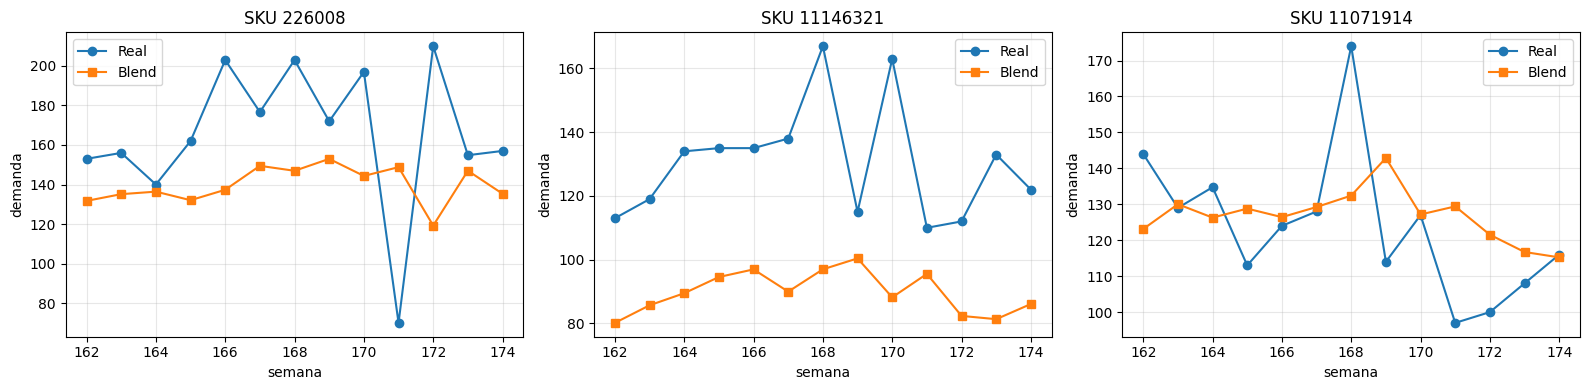

In [10]:
import matplotlib.pyplot as plt

top = [r["SKU"] for r in pred.groupBy("SKU").agg(F.sum("demanda").alias("t"))
       .orderBy(F.desc("t")).limit(3).collect()]
pdf = pred.filter(F.col("SKU").isin(top)).select("SKU", "semana", "demanda", "p_blend").toPandas()

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, sku in zip(axes, top):
    sub = pdf[pdf["SKU"] == sku].sort_values("semana")
    ax.plot(sub["semana"], sub["demanda"], marker="o", label="Real")
    ax.plot(sub["semana"], sub["p_blend"], marker="s", label="Blend")
    ax.set_title(f"SKU {sku}")
    ax.set_xlabel("semana"); ax.set_ylabel("demanda"); ax.legend(); ax.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

## 10. Pronóstico por SKU para el reabastecimiento

Persistimos, por SKU, la **demanda semanal esperada** (promedio del pronóstico
mezclado en el horizonte de prueba) y la **desviación histórica**, que el
notebook 04 usará para calcular punto de reorden y cantidad a pedir.


In [11]:
pron_sku = pred.groupBy("SKU").agg(F.avg("p_blend").alias("demanda_pred_semanal"))
sigma_sku = feat.groupBy("SKU").agg(
    F.stddev("demanda").alias("sigma_semanal"),
    F.avg("demanda").alias("demanda_hist_prom"),
)
forecast_sku = pron_sku.join(sigma_sku, "SKU").fillna({"sigma_semanal": 0.0})
forecast_sku.write.mode("overwrite").parquet(os.path.join(PARQUET_DIR, "forecast_sku"))
print("Pronostico por SKU guardado:", forecast_sku.count(), "SKUs")
forecast_sku.orderBy(F.desc("demanda_pred_semanal")).show(8)
spark.stop()
print("SparkSession finalizada.")

Pronostico por SKU guardado: 436 SKUs


+--------+--------------------+------------------+------------------+
|     SKU|demanda_pred_semanal|     sigma_semanal| demanda_hist_prom|
+--------+--------------------+------------------+------------------+
|  226008|   139.7492805253709| 35.19860054077954|116.68305901631147|
|11071914|  126.86688688437282| 22.49178597300022|133.56967213114754|
|11106361|   92.11043014197587|14.423986669874479| 91.67930327868852|
|11146321|   89.81580346676222|  52.5047789452073|22.227459016393443|
|11071915|     64.562182477238|15.048242995796347| 57.05327868852459|
|11069308|   59.69548628420686|12.275602518008167| 49.89245109286885|
|11174136|   51.85422502503007|14.283473414740369| 4.639344262295082|
|    7360|   51.61361492995338| 8.885986529650152|           46.9959|
+--------+--------------------+------------------+------------------+
only showing top 8 rows


SparkSession finalizada.
